In [1]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from utils.tv_var.periodic_var import PeriodicVAR, select_order

In [2]:
import pickle
from scipy.signal import find_peaks
from utils.pit.piece_wise_marginal import from_normal

waves_df = pd.read_csv("inputs/waves_bulk.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open("outputs/marginal/transformacion.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

In [3]:
#### Residuos de 04B y modelo de escala + mapeo exportado en 05C
resid = pd.read_csv("outputs/xgb_pit/residuos_horarios.csv", index_col=0, parse_dates=True)
esc = pickle.load(open("outputs/xgb_pit/escala.pkl", "rb"))
bordes, sigma, pools_r, results_u, L = esc["bordes"], esc["sigma"], esc["pools_r"], esc["results_u"], esc["L"]

#### Mismo suavizado de f que en 05C (se guarda en escala.pkl)
SUAVIZADO_H = esc.get("suavizado_h", 1)
if SUAVIZADO_H > 1:
    resid["f"] = resid["f"].rolling(SUAVIZADO_H, center=True, min_periods=1).mean()
    resid["r"] = resid["z"] - resid["f"]
print(f"f suavizada {SUAVIZADO_H} h")

e_u = results_u.resid_["r"].asfreq("h")
ev = e_u.values
inicios = np.flatnonzero(np.convolve(~np.isnan(ev), np.ones(L), "valid") == L)

def ruido_bloques(n, L, rng):
    out = np.empty(n)
    t = 0
    while t < n:
        s = rng.choice(inicios)
        m = min(L, n - t)
        out[t:t + m] = ev[s:s + m]
        t += m
    return out

def mapear(r, dec):
    """Mapeo de cuantiles por decil: r toma la forma de r_oof de su decil."""
    out = np.empty(len(r))
    for k in range(10):
        m = dec == k
        rk = (pd.Series(r.values[m]).rank().values - 0.5) / m.sum()
        out[m] = np.quantile(pools_r[k], rk)
    return pd.Series(out, index=r.index)

f suavizada 13 h


In [4]:
#### TEST 1 — ¿Sobran temporales también en entrenamiento?
#### Simulamos 1985–2025 seguido con la f histórica (OOF hasta 2015, test desde 2016)
f_all = resid.loc["1985-01-01":"2025-12-31", "f"].asfreq("h")
z_all = resid.loc["1985-01-01":"2025-12-31", "z"].asfreq("h")
r_all = resid.loc["1985-01-01":"2025-12-31", "r"].asfreq("h")
hs_all = waves_df.loc["1985":"2025", "VHM0"]
print(f_all.isna().sum(), len(f_all))

dec_all = np.digitize(f_all, bordes)
sig_all = pd.Series(sigma.loc[dec_all].values, index=f_all.index)

0 359400


In [5]:
import time
n_sims = 30
hs_sims, z_sims = [], []

for i in range(n_sims):
    t = time.time()
    rng = np.random.default_rng(i)
    ruido_df = pd.DataFrame(ruido_bloques(len(f_all), L, rng), index=f_all.index, columns=["r"])
    u_i = results_u.simulate(noise=ruido_df, burn=24*30)["r"]
    r_i = mapear(u_i * sig_all, dec_all)
    z_sims.append(f_all + r_i)
    hs_sims.append(hs_desde_z(f_all + r_i))
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")

hs_sims = pd.concat(hs_sims, axis=1)
z_sims = pd.concat(z_sims, axis=1)

sim 00 (9 s)
sim 01 (9 s)
sim 02 (9 s)
sim 03 (9 s)
sim 04 (9 s)
sim 05 (9 s)
sim 06 (11 s)
sim 07 (11 s)
sim 08 (11 s)
sim 09 (8 s)
sim 10 (8 s)
sim 11 (8 s)
sim 12 (8 s)
sim 13 (9 s)
sim 14 (9 s)
sim 15 (9 s)
sim 16 (9 s)
sim 17 (9 s)
sim 18 (9 s)
sim 19 (9 s)
sim 20 (8 s)
sim 21 (9 s)
sim 22 (11 s)
sim 23 (12 s)
sim 24 (9 s)
sim 25 (9 s)
sim 26 (9 s)
sim 27 (9 s)
sim 28 (9 s)
sim 29 (9 s)


In [6]:
#### Temporales por década con un umbral común (q99 de Hs observada 1985–2025)
def n_picos(serie, umbral, sep_h=72):
    return len(find_peaks(serie.values, height=umbral, distance=sep_h)[0])

u = hs_all.quantile(0.99)
hs_f = hs_desde_z(f_all)
decadas = {"1985–1994": ("1985", "1994"), "1995–2004": ("1995", "2004"),
           "2005–2015": ("2005", "2015"), "2016–2025": ("2016", "2025")}

filas = []
for nombre, (a, b) in decadas.items():
    n_anos = int(b) - int(a) + 1
    n_sim = [n_picos(hs_sims.loc[a:b, c], u) * 10 / n_anos for c in hs_sims.columns]
    filas.append({"década": nombre, "obs": n_picos(hs_all.loc[a:b], u) * 10 / n_anos,
                  "solo f": n_picos(hs_f.loc[a:b], u) * 10 / n_anos,
                  "sim med": np.median(n_sim), "sim lo": np.percentile(n_sim, 2.5), "sim hi": np.percentile(n_sim, 97.5),
                  "q99 obs": hs_all.loc[a:b].quantile(0.99), "q99 sim": hs_sims.loc[a:b].quantile(0.99).median()})
tabla_dec = pd.DataFrame(filas).set_index("década")
print(f"umbral común: {u:.2f} m  (temporales por cada 10 años)")
print(tabla_dec.round(2))

umbral común: 2.64 m  (temporales por cada 10 años)
             obs  solo f  sim med  sim lo  sim hi  q99 obs  q99 sim
década                                                             
1985–1994  51.00   21.00    67.00   55.72   75.28     2.53     2.78
1995–2004  70.00   24.00    71.50   61.62   80.28     2.76     2.87
2005–2015  70.91   25.45    80.91   70.41   91.00     2.66     2.90
2016–2025  57.00   23.00    71.00   61.45   83.55     2.61     2.86


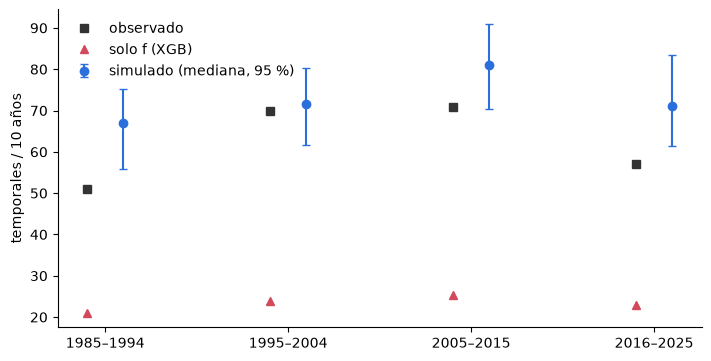

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
x = np.arange(len(tabla_dec))
ax.errorbar(x + 0.1, tabla_dec["sim med"], yerr=[tabla_dec["sim med"] - tabla_dec["sim lo"], tabla_dec["sim hi"] - tabla_dec["sim med"]],
            fmt="o", color="#2a6fdb", capsize=3, label="simulado (mediana, 95 %)")
ax.plot(x - 0.1, tabla_dec["obs"], "s", color="0.2", label="observado")
ax.plot(x - 0.1, tabla_dec["solo f"], "^", color="#d1495b", label="solo f (XGB)")
ax.set(xticks=x, xticklabels=tabla_dec.index, ylabel="temporales / 10 años")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

In [8]:
#### TEST 2 — ¿La regresión se pasa en sus propios picos? r en los máximos locales de f
filas = []
for per, (a, b) in {"oof (1985–2015)": ("1985", "2015"), "test (2016–2025)": ("2016", "2025")}.items():
    f_p, r_p, z_p = f_all.loc[a:b], r_all.loc[a:b], z_sims.loc[a:b]
    for q in [0.5, 0.9, 0.95, 0.99]:
        pk, _ = find_peaks(f_p.values, height=f_p.quantile(q), distance=72)
        r_sim_pk = (z_p.iloc[pk].sub(f_p.iloc[pk], axis=0)).mean()          # r simulado en los mismos picos
        filas.append({"periodo": per, "picos de f >": f"q{int(q*100)}", "n": len(pk),
                      "r real": r_p.iloc[pk].mean(), "r sim": r_sim_pk.median()})
print(pd.DataFrame(filas).set_index(["periodo", "picos de f >"]).round(3))

                                  n  r real  r sim
periodo          picos de f >                     
oof (1985–2015)  q50           1863   0.094  0.066
                 q90            753   0.053  0.032
                 q95            468  -0.004  0.031
                 q99            126  -0.050  0.042
test (2016–2025) q50            622   0.051  0.071
                 q90            243   0.005  0.045
                 q95            157  -0.029  0.028
                 q99             43  -0.264  0.041


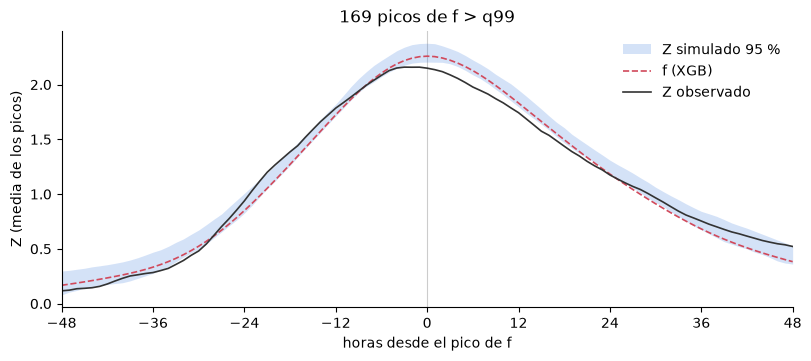

In [9]:
#### Composición alrededor de los picos de f (> q99, todo el periodo): ¿Z real queda por debajo de f?
ventana = np.arange(-48, 49)
pk, _ = find_peaks(f_all.values, height=f_all.quantile(0.99), distance=72)
pk = pk[(pk > 48) & (pk < len(f_all) - 49)]

def compuesto(serie):
    return np.nanmean([serie.values[i + ventana] for i in pk], axis=0)

c_f, c_z = compuesto(f_all), compuesto(z_all)
c_sim = np.array([compuesto(z_sims[c]) for c in z_sims.columns])

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.fill_between(ventana, np.percentile(c_sim, 2.5, axis=0), np.percentile(c_sim, 97.5, axis=0),
                color="#2a6fdb", alpha=0.2, lw=0, label="Z simulado 95 %")
ax.plot(ventana, c_f, color="#d1495b", lw=1.2, ls="--", label="f (XGB)")
ax.plot(ventana, c_z, color="0.2", lw=1.2, label="Z observado")
ax.axvline(0, color="0.8", lw=0.8, zorder=0)
ax.set(xlabel="horas desde el pico de f", ylabel="Z (media de los picos)", xticks=np.arange(-48, 49, 12), xlim=(-48, 48),
       title=f"{len(pk)} picos de f > q99")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


R² del filtro lineal de f sobre r (oof): 0.015
R² del filtro lineal de f sobre r (test): 0.006


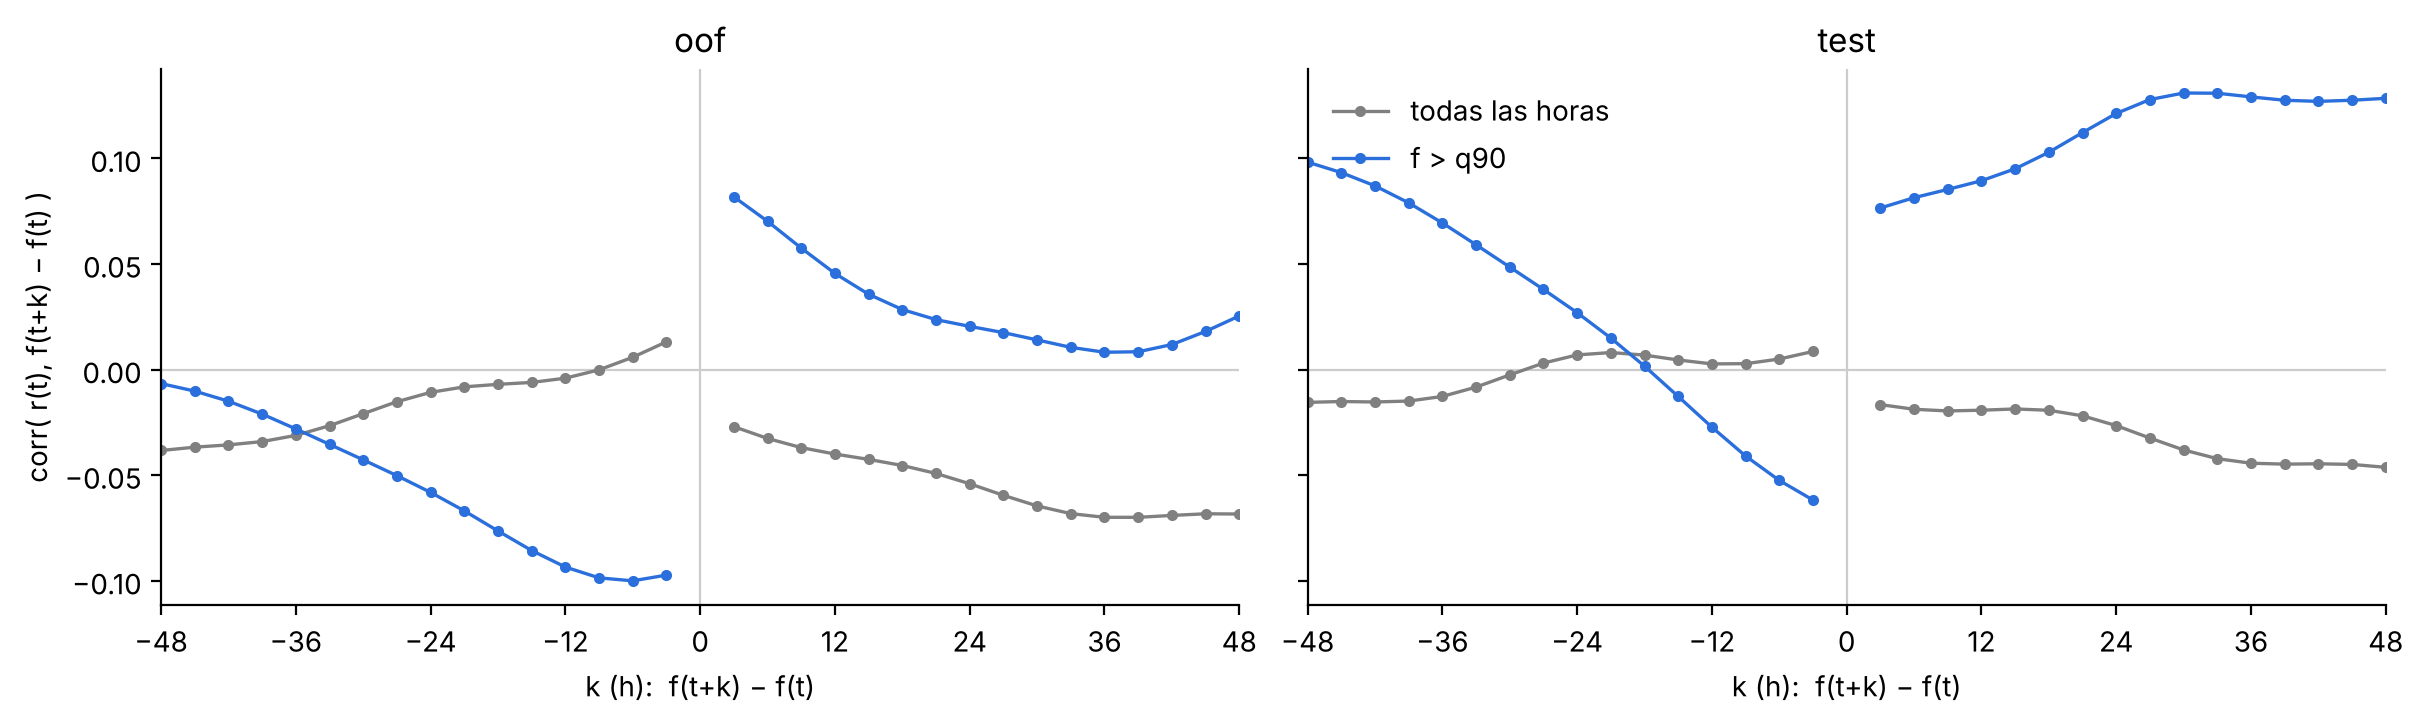

In [2]:
#### TEST 3 — ¿El residuo depende de f en otros instantes? (motiva una función de transferencia)
#### corr( r(t), f(t+k) − f(t) ): >0 en k>0 → Z se adelanta a f; en k<0 → Z arrastra inercia
from sklearn.linear_model import LinearRegression

lags_k = np.arange(-48, 49, 3)
cc = {}
for per, (a, b) in {"oof": ("1985", "2015"), "test": ("2016", "2025")}.items():
    f_p, r_p = f_all.loc[a:b], r_all.loc[a:b]
    alto = f_p > f_p.quantile(0.9)                                     # solo en condiciones de temporal
    d_f = {k: f_p.shift(-k) - f_p for k in lags_k}
    cc[per] = pd.DataFrame({"todo": [r_p.corr(d_f[k]) for k in lags_k],
                            "f > q90": [r_p[alto].corr(d_f[k][alto]) for k in lags_k]}, index=lags_k)

#### ¿Cuánto de r explicaría un filtro lineal de f? (ajuste en oof, evaluado en test)
k_fir = np.arange(-48, 49, 6)
def matriz(f_p):
    return pd.DataFrame({f"d{k}": f_p.shift(-k) - f_p for k in k_fir if k != 0}).assign(f=f_p)
X_o, X_t = matriz(f_all.loc["1985":"2015"]), matriz(f_all.loc["2016":"2025"])
ok_o, ok_t = X_o.notna().all(axis=1), X_t.notna().all(axis=1)
fir = LinearRegression().fit(X_o[ok_o], r_all.loc[X_o.index][ok_o])
for per, Xp, okp in [("oof", X_o, ok_o), ("test", X_t, ok_t)]:
    rp = r_all.loc[Xp.index][okp]
    print(f"R² del filtro lineal de f sobre r ({per}): {1 - (rp - fir.predict(Xp[okp])).var() / rp.var():.3f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True, constrained_layout=True)
for ax, per in zip(axs, ["oof", "test"]):
    ax.plot(lags_k, cc[per]["todo"], "o-", color="0.5", ms=3, lw=1.2, label="todas las horas")
    ax.plot(lags_k, cc[per]["f > q90"], "o-", color="#2a6fdb", ms=3, lw=1.2, label="f > q90")
    ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.axvline(0, color="0.8", lw=0.8, zorder=0)
    ax.set(title=per, xlabel="k (h):  f(t+k) − f(t)", xticks=np.arange(-48, 49, 12), xlim=(-48, 48))
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("corr( r(t), f(t+k) − f(t) )")
axs[1].legend(frameon=False, loc="upper left")
plt.show()